# DocuMind - receipts: detector (YOLO) from the labelled boxes to the values

Same idea as `train_documind.ipynb`: the notebook only calls the package (`documind/`), run it top to bottom with the kernel of your `ai_env`.

```
data/processed/receipts_yolo (already prepared)  ->  [documind.training.train_receipts]  ->  models/receipts_yolo.pt
picture  ->  [3 documind.inference.receipts: detector + Tesseract on each box]  ->  store / date / total / receipt number / item rows
```
Classes: read from `data/processed/receipts_yolo/data.yaml`. With `generate_receipts.py` there are 13: `store_name, address, phone, date, time, receipt_number, item_name, item_qty, item_price, subtotal, tax, total, payment_method`.
Training needs a GPU to be comfortable (your RTX 3080 Laptop is fine once PyTorch is the CUDA build, see the GPU check below); on a CPU it works but takes hours.

In [1]:
import json, os, sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from PIL import Image
# Make the project root importable when the notebook is opened from a subfolder.
ROOT = Path.cwd()
while not (ROOT / "documind").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

if (ROOT / "documind").is_dir():
    os.chdir(ROOT)
    if str(ROOT) not in sys.path:
        sys.path.insert(0, str(ROOT))
    print(f"project root: {ROOT}")
else:
    raise FileNotFoundError(
        "Could not find the project root containing 'documind/'. "
        "Open the notebook from the repo root or install the project with: %pip install -e ."
    )

from documind.config import MODELS_DIR, PROCESSED_DIR, RAW_DIR, REPORTS_DIR

project root: c:\Users\aa\Downloads\documind_backend (2)\documind_backend


If a package is missing (first run): `pip install -r requirements-receipts.txt` in a terminal with the `ai_env` activated (Ultralytics brings PyTorch: big download).

## GPU check (run this first)
Ultralytics only uses the GPU if PyTorch is a **CUDA build** and the NVIDIA driver works. `pip install ultralytics` often installs the CPU-only PyTorch on Windows, so check before training.

If the check below stops with an error, fix it in a terminal with `ai_env` activated, then **restart the kernel**:
```
pip uninstall -y torch torchvision torchaudio
pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
```

In [2]:
import torch

REQUIRE_GPU = True   # True = stop here if no GPU is found (instead of silently training for hours on the CPU)

print("python executable :", sys.executable)          # must be inside your ai_env
print("torch             :", torch.__version__)       # ending with +cpu = CPU-only build
print("torch CUDA build  :", torch.version.cuda)      # None = CPU-only build
print("cuda available    :", torch.cuda.is_available())

if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f"gpu               : {props.name} ({props.total_memory / 1024**3:.1f} GB VRAM)")
    DEVICE = 0
else:
    DEVICE = "cpu"
    msg = ("No usable GPU for PyTorch. Check, in this order:\n"
           "  1. torch version ends with '+cpu' / CUDA build is None -> reinstall the CUDA build (cell above)\n"
           "  2. python executable is not your ai_env -> Kernel > Change kernel\n"
           "  3. 'nvidia-smi' fails in a terminal -> update the NVIDIA driver")
    if REQUIRE_GPU:
        raise RuntimeError(msg)
    print("WARNING (training will run on the CPU):\n" + msg)

python executable : c:\Users\aa\anaconda3\envs\pytorch_gpu\python.exe
torch             : 2.6.0+cu124
torch CUDA build  : 12.4
cuda available    : True
gpu               : NVIDIA GeForce RTX 3080 Laptop GPU (8.0 GB VRAM)


## Settings

In [3]:
from documind.data.prepare_receipts import read_names_from_yaml
CLASS_NAMES = read_names_from_yaml(PROCESSED_DIR / "receipts_yolo" / "data.yaml") or ["store", "date", "total", "receipt_no", "item"]   # class ids 0..N-1, read from the prepared data
print(len(CLASS_NAMES), "classes:", CLASS_NAMES)

MODEL = "yolo11s.pt"   # yolo11n (fastest) < yolo11s < yolo11m (most accurate, more GPU memory)
EPOCHS =15           # 50 full epochs (8,000 train pictures at imgsz 960: about 3.5 min per epoch, so expect about 3 h)
TARGET = 0.90         # score to reach on val AND test (mAP50), checked after the evaluation
IMGSZ = 960            # receipts are tall and the boxes are thin: 960 or 1280 is much better than 640
BATCH = 8              # lower it (4) on 'CUDA out of memory'; -1 = automatic
PATIENCE = 100         # 100 = never stop early (best.pt is still the best epoch); 20 = stop after 20 epochs without progress
NAME = "receipts"
# DEVICE (0 = first GPU, or "cpu") was set by the GPU check above
WORKERS = max(2, min(8, os.cpu_count() or 2))   # data-loader processes: the first run used 2 and the GPU probably waited for the data
CACHE = False          # "ram" or "disk" decode every picture once (needs about 9 GB): faster epochs
FRACTION = 1.0         # 0.3 = train on 30 % of the pictures: quick run to compare settings


13 classes: ['store_name', 'address', 'phone', 'date', 'time', 'receipt_number', 'item_name', 'item_qty', 'item_price', 'subtotal', 'tax', 'total', 'payment_method']


## Look at the data
The data was prepared in an earlier run (the prepare step is no longer part of this notebook, so your label corrections in `data/processed/receipts_yolo` are never overwritten). If the boxes in the pictures do not sit on the right things, **stop here**.

,train,val,test
store_name,8000,1000,1000
address,16000,2000,2000
phone,8000,1000,1000
date,8000,1000,1000
time,8000,1000,1000
receipt_number,8000,1000,1000
item_name,52181,6530,6585
item_qty,52181,6530,6585
item_price,52181,6530,6585
subtotal,8000,1000,1000


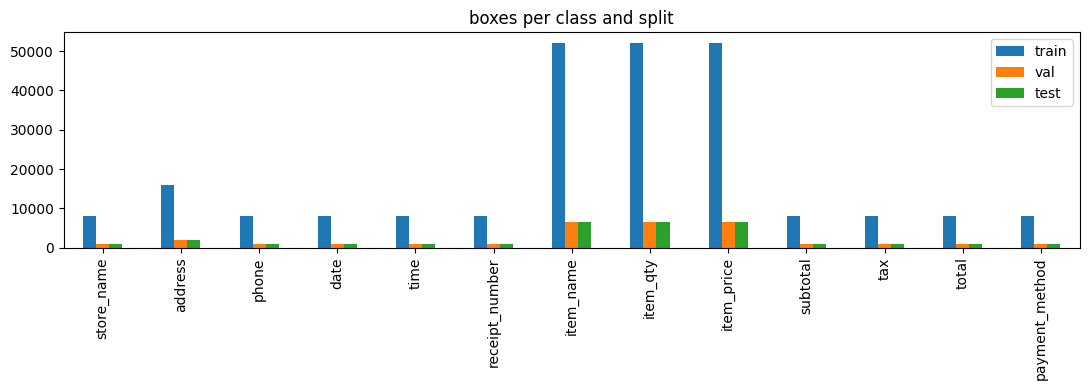

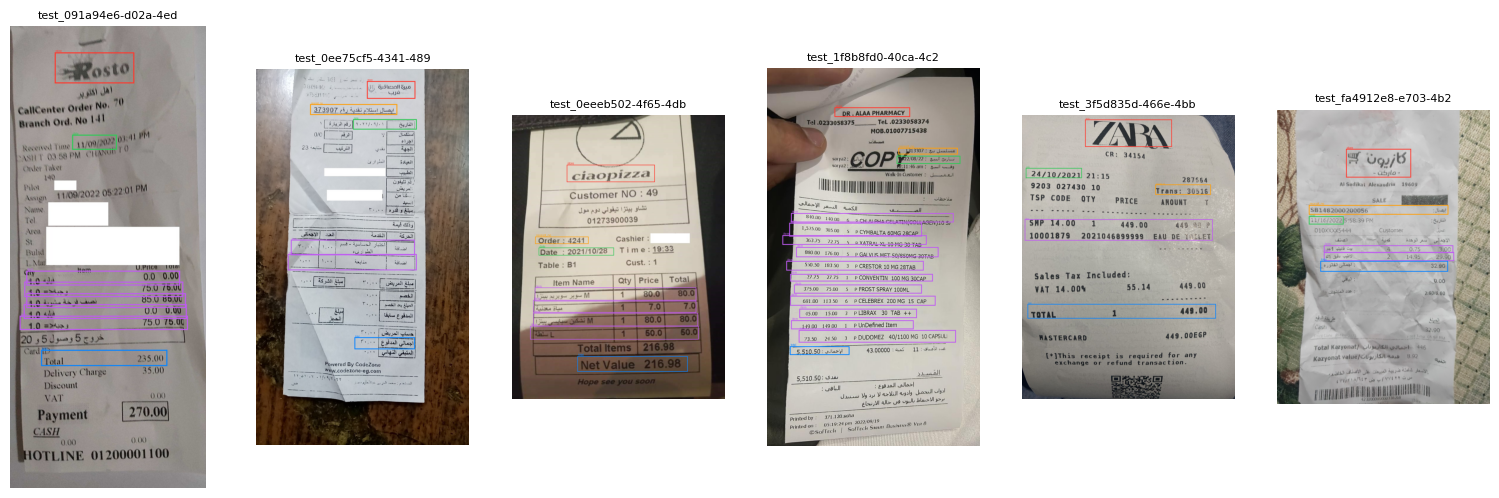

In [4]:
DATA_ROOT = PROCESSED_DIR / "receipts_yolo"
DATA_YAML = DATA_ROOT / "data.yaml"
assert DATA_YAML.exists(), "prepared data not found: run  python -m documind.data.prepare_receipts  once in a terminal"

counts = {}
for split in ("train", "val", "test"):
    n = [0] * len(CLASS_NAMES)
    for p in (DATA_ROOT / split / "labels").glob("*.txt"):
        for line in p.read_text().splitlines():
            if line.strip():
                parts = line.split()
                if len(parts) < 5:
                    continue
                try:
                    cls_id = int(float(parts[0]))
                except ValueError:
                    continue
                if 0 <= cls_id < len(n):
                    n[cls_id] += 1
    counts[split] = n
df = pd.DataFrame(counts, index=CLASS_NAMES)
display(df)
df.plot(kind="bar", figsize=(11, 4), title="boxes per class and split"); plt.tight_layout(); plt.show()
prev = sorted((REPORTS_DIR / "receipts_preview").glob("*.png"))[:6]
if prev:
    fig, ax = plt.subplots(1, len(prev), figsize=(3.2 * len(prev), 6))
    for a, p in zip(ax if len(prev) > 1 else [ax], prev):
        a.imshow(Image.open(p)); a.set_title(p.stem[:22], fontsize=8); a.axis("off")
    plt.show()

## STEP 2 - train
Augmentation chosen for receipts: no left-right flip, small rotation / perspective (phone pictures), brightness changes, mosaic off for the last 15 epochs.

The device is passed to your `train()` wrapper when it accepts a `device` argument. If it does not, add `device=None` to its signature and forward it to `model.train(device=device, ...)` in `documind/training/train_receipts.py`. Ultralytics already picks GPU 0 by itself when CUDA works, so the first lines of the training log must show `CUDA:0 (NVIDIA GeForce RTX 3080 ...)`.

**Speed check while an epoch runs:** open Task Manager > Performance > GPU (look at the *CUDA* or *Compute* graph) or run `nvidia-smi -l 1` in a terminal.
Below about 70 % the GPU is waiting for the data loader: raise `WORKERS` or set `CACHE = "ram"` / `"disk"`.
Above 90 % it is the GPU: use `MODEL = "yolo11n.pt"` or `IMGSZ = 800` and compare with `FRACTION = 0.3` runs first.

In [5]:
import inspect
import os

import torch
from documind.training import train_receipts   # the project root is already on sys.path (first code cell)

def _accepts(fn, arg):
    params = inspect.signature(fn).parameters
    return arg in params or any(p.kind is inspect.Parameter.VAR_KEYWORD for p in params.values())

# fallback definitions in case this cell is run before the settings cell
for _name, _value in {
    "MODEL": "yolo11s.pt",
    "EPOCHS": 15,
    "IMGSZ": 960,
    "BATCH": 8,
    "PATIENCE": 100,
    "NAME": "receipts",
    "WORKERS": max(2, min(8, os.cpu_count() or 2)),
    "CACHE": False,
    "FRACTION": 1.0,
}.items():
    if _name not in globals():
        globals()[_name] = _value

if "DEVICE" not in globals():
    DEVICE = 0 if torch.cuda.is_available() else "cpu"

train_kwargs = dict(
    model=MODEL,
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    patience=PATIENCE,
    name=NAME,
    workers=WORKERS,
    cache=CACHE,
    fraction=FRACTION,
)
if _accepts(train_receipts.train, "device"):
    train_kwargs["device"] = DEVICE
else:
    print("note: train() has no 'device' argument -> Ultralytics will choose the device by itself")

weights = train_receipts.train(**train_kwargs)
print("best weights:", weights)

New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.204  Python-3.10.20 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3080 Laptop GPU, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\Users\aa\Downloads\documind_backend (2)\documind_backend\data\processed\receipts_yolo\data.yaml, degrees=4.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.5, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01

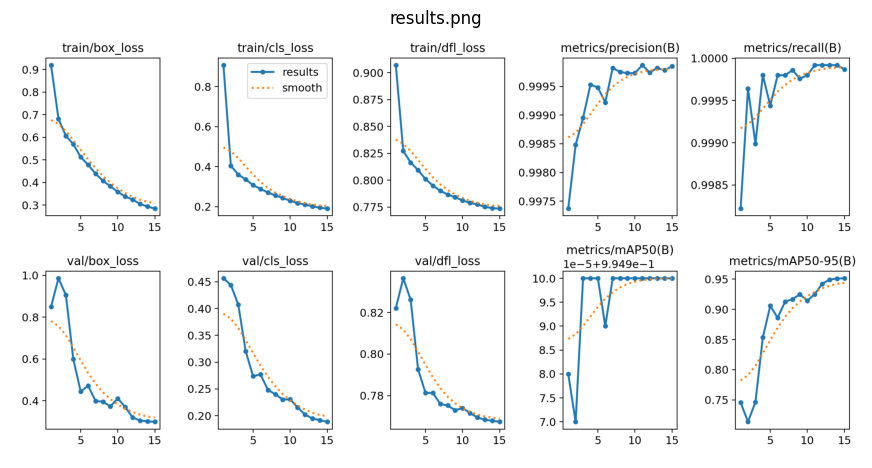

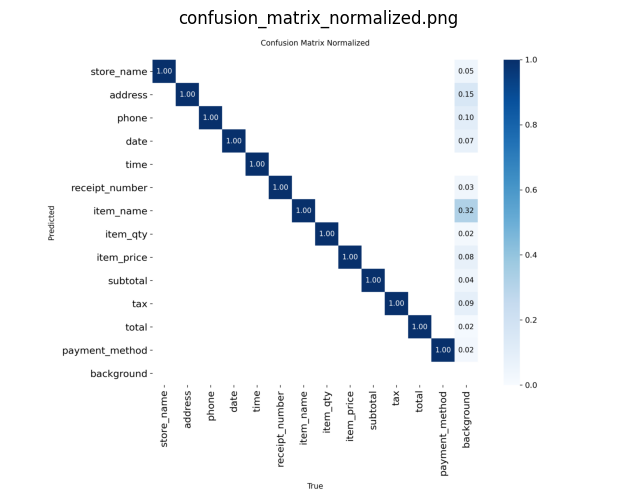

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

run_dir = train_receipts.RUNS_DIR / NAME
for f in ("results.png", "confusion_matrix_normalized.png"):
    path = run_dir / f
    if path.exists():
        plt.figure(figsize=(11, 6))
        plt.imshow(Image.open(path))
        plt.axis("off")
        plt.title(f)
        plt.show()

## Evaluate on val AND test
`test` was never used for training or for choosing the best epoch: it is the honest number. Read the **per-class** rows: a good average can hide a class that never works (thin `total` / `date` boxes are the usual suspects).

**`found_rate` is the number to follow for the product** (new column): store / date / total / receipt_no = is the most confident box of that class on a labelled box (IoU >= 0.5); item = share of labelled rows found. mAP also counts every correct box that has *no label* as a mistake, and in this dataset many labels are missing, so mAP50 cannot reach 1 however good the model is.

In [7]:
import pandas as pd
from IPython.display import display

eval_kwargs = dict(imgsz=IMGSZ)
if _accepts(train_receipts.evaluate, "device"):
    eval_kwargs["device"] = DEVICE
rows = train_receipts.evaluate(weights, **eval_kwargs)
display(pd.DataFrame(rows).round(3))
# did we reach the target (val AND test)?  mAP50 is the strict number, found_rate the one closer to what the user sees
for metric in ("mAP50", "found_rate"):
    print(f"--- {metric}")
    train_receipts.print_verdict(train_receipts.check_target(rows, TARGET, metric))


Ultralytics 8.4.204  Python-3.10.20 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3080 Laptop GPU, 8192MiB)
YOLO11s summary (fused): 100 layers, 9,417,831 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 489.6±470.9 MB/s, size: 76.9 KB)
val: Scanning C:\Users\aa\Downloads\documind_backend (2)\documind_backend\data\processed\receipts_yolo\val\labels.cache... 1000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 1.6it/s 40.6s0.2ss0
                   all       1000      30590          1          1      0.995      0.964
Speed: 1.6ms preprocess, 6.4ms inference, 0.0ms loss, 1.7ms postprocess per image
Ultralytics 8.4.204  Python-3.10.20 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3080 Laptop GPU, 8192MiB)
YOLO11s summary (fused): 100 layers, 9,417,831 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.1±

,split,class,precision,recall,mAP50,mAP50-95,found_rate
0,val,ALL,1.0,1.000,0.995,0.964,1.000
1,val,store_name,1.0,0.999,0.995,0.937,1.000
2,val,address,1.0,1.000,0.995,0.963,1.000
3,val,phone,1.0,1.000,0.995,0.978,1.000
4,val,date,1.0,1.000,0.995,0.976,1.000
5,val,time,1.0,1.000,0.995,0.988,1.000
6,val,receipt_number,1.0,1.000,0.995,0.978,1.000
7,val,item_name,1.0,1.000,0.995,0.955,1.000
8,val,item_qty,1.0,1.000,0.995,0.915,1.000
9,val,item_price,1.0,1.000,0.995,0.985,1.000


--- mAP50
  val   mAP50 = 0.995   OK
  test  mAP50 = 0.995   OK

TARGET REACHED: mAP50 >= 0.90 on val and test.
Careful: val and test come from the same generator as train, so this proves the model learned the generated layouts. Try real photos (python -m documind.inference.receipts photo.jpg) before trusting it.
--- found_rate
  val   found_rate = 1.000   OK
  test  found_rate = 1.000   OK

TARGET REACHED: found_rate >= 0.90 on val and test.
Careful: val and test come from the same generator as train, so this proves the model learned the generated layouts. Try real photos (python -m documind.inference.receipts photo.jpg) before trusting it.


## Audit the labels (the surest way to a higher score)
Lists the confident predictions that match **no label** (probably a *missing* label: the date is printed but nobody labelled it) and the labelled boxes the model does not see at all (probably a *wrong* label).
Open the pictures of `reports/receipts_audit/val/` (white = label, colour = prediction) and fix the label files in `data/processed/receipts_yolo/<split>/labels` (keep a copy first). Do not rebuild the data from `data/raw` afterwards: it would overwrite the fixes. Do it on **val and test** too: a score measured on incomplete labels is too low.

,class,kind,detail,count
0,store_name,WRONG label?,labelled box the model does not see,1


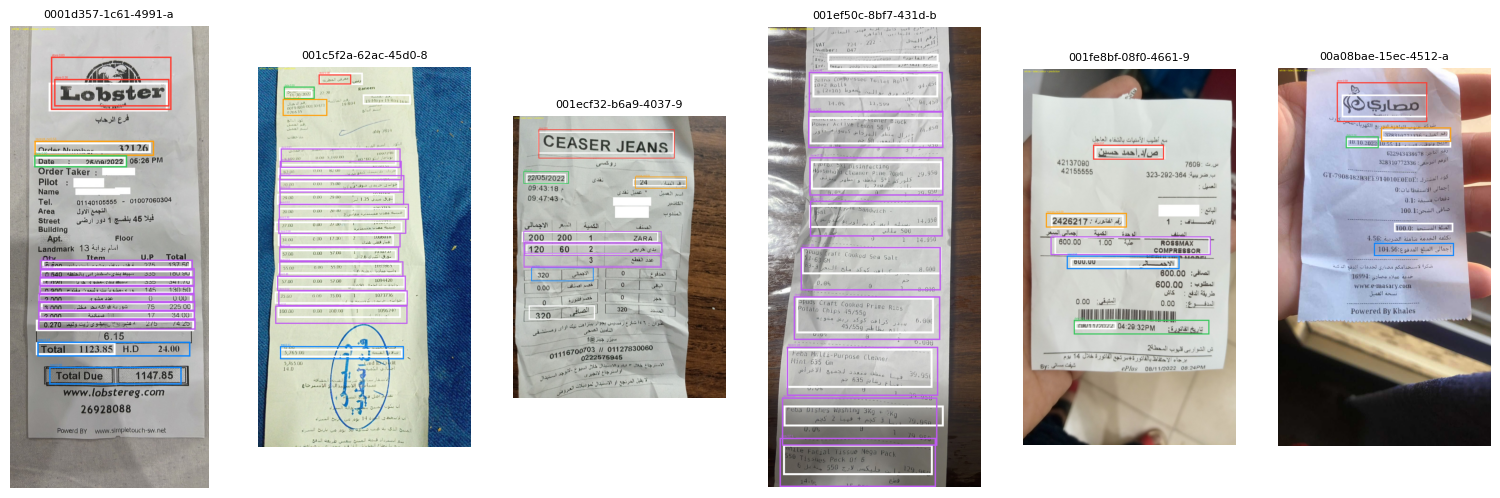

In [11]:
import subprocess
for split in ("val",):
    subprocess.run([sys.executable, "-m", "documind.training.audit_receipts", "--split", split, "--imgsz", str(IMGSZ), "--device", str(DEVICE)], check=True)
sus = pd.read_csv(REPORTS_DIR / "receipts_audit" / "val_suspects.csv")
display(sus.groupby(["class", "kind", "detail"], dropna=False).size().rename("count").reset_index().sort_values("count", ascending=False))
pics = sorted((REPORTS_DIR / "receipts_audit" / "val").glob("*.png"))[:6]
fig, ax = plt.subplots(1, max(1, len(pics)), figsize=(3.2 * max(1, len(pics)), 6))
for a, p in zip(ax if len(pics) > 1 else [ax], pics):
    a.imshow(Image.open(p)); a.set_title(p.stem[:20], fontsize=8); a.axis("off")
plt.show()

## See the predictions on test pictures

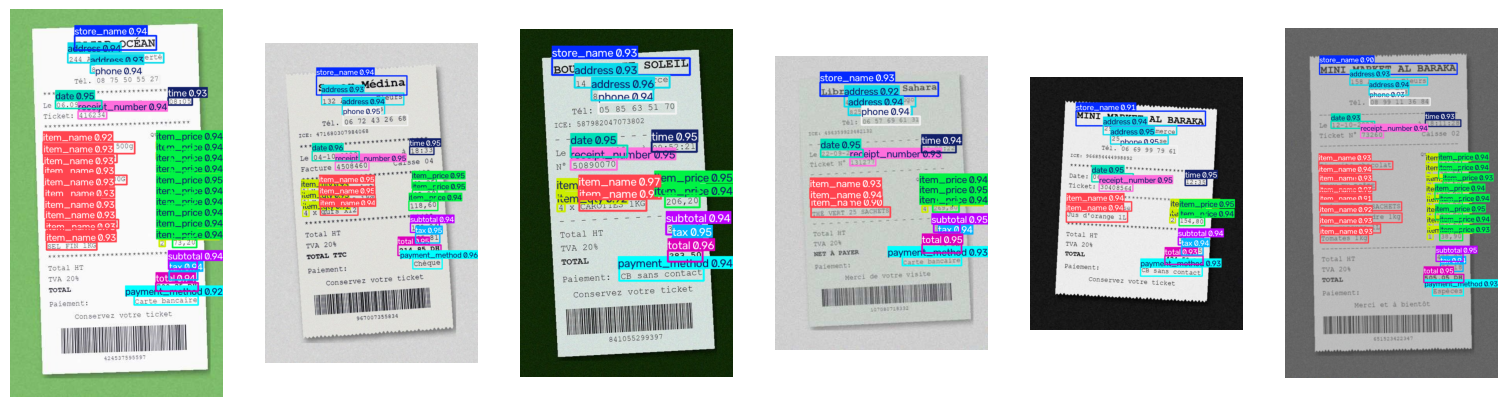

In [9]:
from ultralytics import YOLO
model = YOLO(str(weights))
test_imgs = sorted((PROCESSED_DIR / "receipts_yolo" / "test" / "images").glob("*.jpg"))[:6]
res = model.predict(source=[str(p) for p in test_imgs], imgsz=IMGSZ, conf=0.25, device=DEVICE, verbose=False)
fig, ax = plt.subplots(1, len(res), figsize=(3.2 * len(res), 6))
for a, r in zip(ax if len(res) > 1 else [ax], res):
    a.imshow(r.plot()[..., ::-1]); a.axis("off")
plt.show()

## STEP 3 - from boxes to values
The detector says **where** the store, date, total, receipt number and item rows are; Tesseract (settings of your `.env`) reads **what** is written there.
Arabic receipts: install the Tesseract data `ara` and put `RECEIPT_OCR_LANG=eng+ara` in `.env`.

In [10]:
from documind.inference.receipts import read_receipt
for p in test_imgs[:3]:
    print(p.name)
    print(json.dumps(read_receipt(p, model=model), ensure_ascii=False, indent=2)[:1500], "\n")

receipt_009000.jpg
{
  "date": {
    "value": "06.09.2026",
    "raw_text": "06.09.2026",
    "box_confidence": 0.95,
    "bbox": [
      92.6,
      186.5,
      186.5,
      202.4
    ]
  },
  "store": {
    "value": "BAZAR OCEAN",
    "raw_text": "BAZAR OCEAN",
    "box_confidence": 0.94,
    "bbox": [
      131.3,
      54.3,
      297.6,
      83.1
    ]
  },
  "tax": {
    "value": "123,21",
    "raw_text": "123,21",
    "box_confidence": 0.94,
    "bbox": [
      323.3,
      534.8,
      381.7,
      551.7
    ]
  },
  "phone": {
    "value": "0875505527",
    "raw_text": "0875505527",
    "box_confidence": 0.94,
    "bbox": [
      173.9,
      135.3,
      304.4,
      152.4
    ]
  },
  "subtotal": {
    "value": "616,04",
    "raw_text": "616,04",
    "box_confidence": 0.94,
    "bbox": [
      322.9,
      512.5,
      380.7,
      529.6
    ]
  },
  "total": {
    "value": "739,25",
    "raw_text": "739,25",
    "box_confidence": 0.94,
    "bbox": [
      296.9,
      557

### Notes
- The model is saved in `models/receipts_yolo.pt`, the scores in `reports/receipts_report.json` (both are git-ignored like the rest).
- **Class meanings** were read from one example picture. Check them on a few other pictures in the preview.
- **Item rows** are detected as whole lines; splitting a row into quantity / unit price / amount is a second step.
- **GPU memory:** the RTX 3080 Laptop has 8 or 16 GB. With `yolo11s`, `IMGSZ = 960`, `BATCH = 8` it should fit; on `CUDA out of memory` lower `BATCH` to 4.
- **Licence:** Ultralytics YOLO is AGPL-3.0 (a commercial licence exists): fine for a university project, read it before a commercial use.
- Command-line version of the same steps: `python -m documind.training.train_receipts`, `python -m documind.inference.receipts ticket.jpg`.